In [1]:
import os

# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from PIL import Image

from lecture_utils import get_device, set_seed, load_stl10, load_flickr30k, STL10_CLASSES
from vision_transformer import VisionTransformer
from vision_language import clip_loss, siglip_loss, load_siglip_vision, pixel_shuffle

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
DATA_DIR = "../../data"
RESULTS_DIR = "results"      # small result tables of all computations (part of the repo)
# The computations of this lecture (evaluation of pretrained CLIP / SigLIP models on 5 datasets and 31 short training
# runs on Flickr30k) take ~45 GPU-minutes on an RTX 5090, so they are NOT started from the notebook.
# Launch them from a terminal in this folder:
#     python experiments.py --list              # what will be run
#     python experiments.py --gpus 0            # run everything (finished runs are skipped)
# The notebook only reads the logs they write to `results/`. The other cells download two pretrained models
# (CLIP ViT-B/16 and SigLIP 2 ViT-B/16, ~2 GB) and run in under a minute.

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE}")

torch 2.11.0+cu130 | timm 1.0.30 | device: cuda


# Agenda

1. [Vision encoders for VLMs](#VLM)
2. [CLIP and SigLIP: learning from image-text pairs](#Losses)
3. [Experiment: our own dual encoder on Flickr30k](#Training)
4. [Zero-shot classification](#ZeroShot)
5. [Image-text retrieval and the shared embedding space](#Retrieval)
6. [Transfer to downstream tasks](#Transfer)
7. [Summary and self-check questions](#Summary)

# Resources

**Contrastive image-text pre-training**
- [CLIP: Learning Transferable Visual Models From Natural Language Supervision (Radford et al., 2021)](https://arxiv.org/abs/2103.00020)
- [ALIGN: Scaling Up Visual and Vision-Language Representation Learning With Noisy Text Supervision (Jia et al., 2021)](https://arxiv.org/abs/2102.05918)
- [LiT: Zero-Shot Transfer with Locked-image text Tuning (Zhai et al., 2022)](https://arxiv.org/abs/2111.07991)
- [SigLIP: Sigmoid Loss for Language Image Pre-Training (Zhai et al., 2023)](https://arxiv.org/abs/2303.15343)
- [SigLIP 2: Multilingual Vision-Language Encoders with Improved Semantic Understanding, Localization, and Dense Features (Tschannen et al., 2025)](https://arxiv.org/abs/2502.14786)
- [Mind the Gap: the modality gap in contrastive representation learning (Liang et al., 2022)](https://arxiv.org/abs/2203.02053)
- [Reproducible scaling laws for contrastive language-image learning (OpenCLIP; Cherti et al., 2023)](https://arxiv.org/abs/2212.07143)
- Data: [MetaCLIP (Xu et al., 2023)](https://arxiv.org/abs/2309.16671), [Data Filtering Networks (Fang et al., 2023)](https://arxiv.org/abs/2309.17425)

**Vision encoders for VLMs**
- [LLaVA: Visual Instruction Tuning (Liu et al., 2023)](https://arxiv.org/abs/2304.08485)
- [PaliGemma (Beyer et al., 2024)](https://arxiv.org/abs/2407.07726)
- [Cambrian-1: A Fully Open, Vision-Centric Exploration of Multimodal LLMs (Tong et al., 2024)](https://arxiv.org/abs/2406.16860)
- [AIMv2: Multimodal Autoregressive Pre-training of Large Vision Encoders (Fini et al., 2024)](https://arxiv.org/abs/2411.14402)
- [Perception Encoder (Bolya et al., 2025)](https://arxiv.org/abs/2504.13181)
- [Scaling Language-Free Visual Representation Learning (Web-SSL; Fan et al., 2025)](https://arxiv.org/abs/2504.01017)
- [SmolVLM (Marafioti et al., 2025)](https://arxiv.org/abs/2504.05299) and [nanoVLM](https://github.com/huggingface/nanoVLM) (the simplest VLM code base, ~750 lines)

<a id='VLM'></a>
# Vision encoders for VLMs

Lectures 4 and 5 learned visual features from images alone. This lecture adds **language** as the source of supervision. Captions come for free with images on the web (alt-texts), they are open-vocabulary, and they describe much more than a class label: objects, attributes, relations, text in the image, style.

The main use of such features today is as the **eye of a vision-language model (VLM)**. Almost every open VLM has the same three parts:

```
image ──► vision encoder (a pretrained ViT) ──► projector ──► image tokens ─┐
                                                                             ├──► language model ──► answer
                                          text ──► tokenizer ──► text tokens ─┘
```

The vision encoder is pretrained separately and is usually a ViT trained on image-text pairs:

| VLM | Vision encoder | Pre-training of the encoder |
|---|---|---|
| LLaVA-1.5 (2023), Molmo (2024) | CLIP ViT-L/14, 336 px | contrastive, softmax (CLIP) |
| PaliGemma 1/2 (2024), Idefics2/3 (2024), Gemma 3 (2025) | SigLIP So400m/14 | contrastive, **sigmoid** (SigLIP) |
| SmolVLM (2025) | SigLIP ViT-B/16 (small models), So400m (2.2B) | SigLIP |
| **nanoVLM** (2025) | **SigLIP 2 ViT-B/16, 512 px** | SigLIP 2 |
| Cambrian-1 (2024) | SigLIP + CLIP + DINOv2 + ConvNeXt-CLIP, combined | image-text **and** self-supervised |
| PerceptionLM (2025) | Perception Encoder | contrastive (CLIP-style) + video |

The pre-training methods behind these encoders form four families, and three of them were covered in this module:

* **Contrastive image-text** — CLIP, ALIGN, OpenCLIP, MetaCLIP, DFN, Perception Encoder: InfoNCE of Lecture 4 between an image and its caption. **Sigmoid** variant: SigLIP. *This lecture.*
* **Captioning / generative** — CapPa, CoCa (contrastive + captioning), AIMv2 (autoregressive prediction of patches and text): the encoder is trained through a text decoder.
* **Self-supervised** — DINOv2 / DINOv3 (Lecture 5). Language-free features are better at **dense, spatial** information (depth, correspondence, segmentation), worse at concepts that only text names (OCR, brands, abstract attributes). Web-SSL (2025) shows that DINO-style training scaled to 7B parameters and 2B web images closes much of the VQA gap to CLIP.
* **Combinations** — **SigLIP 2** (2025) is the current default for small VLMs and is SigLIP + a captioning decoder (LocCa: captions, referring expressions, grounded captions) + **self-distillation with an EMA teacher and local-to-global views (DINO, Lecture 5)** + **masked prediction of the teacher's patch features (iBOT, Lecture 5)** in the last 20% of training. The extra objectives were added because pure image-text training gives poor dense features — we will see this in the patch pictures at the end of the lecture.

## The vision path of nanoVLM

[nanoVLM](https://github.com/huggingface/nanoVLM) builds a VLM in a few hundred lines. Its vision encoder ([`models/vision_transformer.py`](https://github.com/huggingface/nanoVLM/blob/main/models/vision_transformer.py)) is a plain ViT — the same blocks as the ViT we wrote in Lecture 1 — into which the weights of `google/siglip2-base-patch16-512` are copied, renaming the parameters and concatenating the separate $q, k, v$ projections into one matrix. We do the same with our own `VisionTransformer`:

* SigLIP has **no [CLS] token**: all outputs are patch tokens. The image embedding of SigLIP comes from an attention-pooling head (MAP) that a VLM throws away.
* The MLP uses the tanh approximation of GELU (the only change to our Lecture 1 ViT).

The VLM keeps **all patch tokens**: at 512 px with $16 \times 16$ patches that is $32 \times 32 = 1024$ tokens of width 768. The **modality projector** makes them affordable for the language model: *pixel shuffle* concatenates every $4 \times 4$ group of neighbouring tokens into one ($1024 \to 64$ tokens of width $16 \cdot 768 = 12288$), and one linear layer maps them to the width of the language model (960 for SmolLM2-360M). Larger images are cut into $512 \times 512$ tiles, each giving 64 tokens, plus one downscaled global view.

In [3]:
def load_siglip_vision(name="google/siglip2-base-patch16-512"):
    """Loads the image tower of a SigLIP / SigLIP 2 checkpoint into the ViT of Lecture 1.

    The same mapping is done by nanoVLM (models/vision_transformer.py). SigLIP has no [CLS] token: the ViT returns
    one token per patch, and these tokens are what a VLM passes to the language model.
    """
    from huggingface_hub import hf_hub_download
    from safetensors import safe_open
    from transformers import AutoConfig

    cfg = AutoConfig.from_pretrained(name).vision_config
    vit = VisionTransformer(img_size=cfg.image_size, patch_size=cfg.patch_size, num_classes=0,
                            embed_dim=cfg.hidden_size, depth=cfg.num_hidden_layers, num_heads=cfg.num_attention_heads,
                            mlp_ratio=cfg.intermediate_size / cfg.hidden_size, global_pool="avg", gelu_approx="tanh")
    sd = {}
    with safe_open(hf_hub_download(name, "model.safetensors"), framework="pt") as f:
        get = lambda k: f.get_tensor("vision_model." + k)
        sd["patch_embed.proj.weight"] = get("embeddings.patch_embedding.weight")
        sd["patch_embed.proj.bias"] = get("embeddings.patch_embedding.bias")
        sd["pos_embed"] = get("embeddings.position_embedding.weight")[None]
        sd["norm.weight"], sd["norm.bias"] = get("post_layernorm.weight"), get("post_layernorm.bias")
        for i in range(cfg.num_hidden_layers):
            src, dst = f"encoder.layers.{i}.", f"blocks.{i}."
            for a, b in [("layer_norm1", "norm1"), ("layer_norm2", "norm2"), ("mlp.fc1", "mlp.fc1"),
                         ("mlp.fc2", "mlp.fc2"), ("self_attn.out_proj", "attn.proj")]:
                for p in ("weight", "bias"):
                    sd[f"{dst}{b}.{p}"] = get(f"{src}{a}.{p}")
            for p in ("weight", "bias"):   # q, k, v are separate in HF and one matrix in our Attention
                sd[f"{dst}attn.qkv.{p}"] = torch.cat([get(f"{src}self_attn.{x}_proj.{p}") for x in "qkv"])
    vit.load_state_dict(sd)
    return vit.eval()


def pixel_shuffle(x, factor=4):
    """nanoVLM's modality projector, first half: (B, N, D) patch tokens on a square grid -> (B, N / f^2, D * f^2).

    Every f x f group of neighbouring tokens is concatenated into one token, so the language model receives
    f^2 times fewer (and wider) image tokens. A linear layer then maps them to the width of the language model.
    """
    B, N, D = x.shape
    h = int(math.isqrt(N))
    assert h * h == N and h % factor == 0
    x = x.reshape(B, h // factor, factor, h // factor, factor, D)           # (B, H', f, W', f, D)
    x = x.permute(0, 1, 3, 2, 4, 5)                                         # (B, H', W', f, f, D)
    return x.reshape(B, (h // factor) ** 2, factor * factor * D)


vit = load_siglip_vision("google/siglip2-base-patch16-512").to(DEVICE)       # the checkpoint of nanoVLM

# check against the HuggingFace implementation
from transformers import AutoModel
hf_vision = AutoModel.from_pretrained("google/siglip2-base-patch16-512").vision_model.eval().to(DEVICE)
x = torch.randn(2, 3, 512, 512, device=DEVICE)
with torch.no_grad():
    tokens, theirs = vit.forward_features(x), hf_vision(pixel_values=x).last_hidden_state
print(f"our ViT with SigLIP 2 weights: {sum(p.numel() for p in vit.parameters()) / 1e6:.1f}M parameters | "
      f"max |difference| to transformers: {(tokens - theirs).abs().max().item():.1e}")

# the shapes of nanoVLM's vision path
projector = nn.Linear(16 * 768, 960, bias=False).to(DEVICE)                   # SmolLM2-360M has width 960
with torch.no_grad():
    image_tokens = projector(pixel_shuffle(tokens, 4))
print(f"image 512x512 -> ViT {tuple(tokens.shape)} -> pixel shuffle {tuple(pixel_shuffle(tokens, 4).shape)} "
      f"-> projector {tuple(image_tokens.shape)}: 64 tokens per image for the language model")
del hf_vision

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.


[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

our ViT with SigLIP 2 weights: 86.4M parameters | max |difference| to transformers: 1.2e-04
image 512x512 -> ViT (2, 1024, 768) -> pixel shuffle (2, 64, 12288) -> projector (2, 64, 960): 64 tokens per image for the language model


<a id='Losses'></a>
# CLIP and SigLIP: learning from image-text pairs

**CLIP** (Radford et al., 2021) trains two encoders on 400M (image, alt-text) pairs from the web: an image tower $f$ (ResNet or ViT) and a text tower $g$ (a transformer). Each is followed by a linear projection into a shared $d$-dimensional space and L2 normalization, $u_i = f(x_i) / \lVert f(x_i) \rVert$, $v_j = g(t_j) / \lVert g(t_j) \rVert$.

In a batch of $B$ pairs, the image $x_i$ must recognise its own caption $t_i$ among the $B$ captions, and the caption its image among the $B$ images:

$$
\mathcal{L}_{\text{CLIP}} = -\frac{1}{2B} \sum_{i=1}^{B} \left[ \log \frac{e^{t\, u_i^\top v_i}}{\sum_{j} e^{t\, u_i^\top v_j}} + \log \frac{e^{t\, u_i^\top v_i}}{\sum_{j} e^{t\, u_j^\top v_i}} \right]
$$

This is the **InfoNCE / NT-Xent loss of SimCLR** (Lecture 4) with the two "views" being an image and its caption: the other $B - 1$ captions of the batch are the negatives. Two details matter in practice: the temperature $1/t$ is **learned** (initialised at 0.07, $t$ clipped at 100), and the batch is very large (32k), because the softmax needs many negatives and the loss needs the full $B \times B$ similarity matrix — gathered from all GPUs.

**SigLIP** (Zhai et al., 2023) replaces the softmax over the batch by an independent **binary** problem for every pair — "do $x_i$ and $t_j$ match?":

$$
\mathcal{L}_{\text{SigLIP}} = -\frac{1}{B} \sum_{i=1}^{B} \sum_{j=1}^{B} \log \sigma\!\left( z_{ij} \left( t\, u_i^\top v_j + b \right) \right), \qquad z_{ij} = \begin{cases} +1 & i = j \\ -1 & i \neq j \end{cases}
$$

* There is **no normalization across the batch**: the loss of a pair does not depend on the other pairs, so it can be computed block by block (each GPU exchanges text embeddings with its neighbours instead of gathering the whole matrix). This makes training cheaper and allows larger batches on the same hardware.
* A learned **bias** $b$ handles the imbalance of $1$ positive versus $B - 1$ negatives per image; it is initialised at $-10$ (with $t = 10$), so that at the start every pair is predicted as "no match" and the many easy negatives do not dominate the first steps.
* The paper finds the sigmoid loss **better than softmax at small batch sizes** and equal at large ones, with no gain beyond a batch of 32k.

In [4]:
def clip_loss(image_emb, text_emb, logit_scale):
    """Symmetric InfoNCE. image_emb, text_emb: (B, D) L2-normalized, row i of both is a matching pair.

    Every image is classified among the B texts of the batch and every text among the B images.
    """
    logits = logit_scale.exp() * image_emb @ text_emb.T                    # (B, B) scaled cosine similarities
    labels = torch.arange(len(logits), device=logits.device)
    return (F.cross_entropy(logits, labels) + F.cross_entropy(logits.T, labels)) / 2


def siglip_loss(image_emb, text_emb, logit_scale, logit_bias):
    """Sigmoid loss: every (image, text) pair of the batch is an independent binary problem, match or not.

    No softmax over the batch: there is no normalization across pairs, so the loss does not need the full
    similarity matrix at once (it can be computed in chunks across devices).
    """
    logits = logit_scale.exp() * image_emb @ text_emb.T + logit_bias       # (B, B)
    labels = 2 * torch.eye(len(logits), device=logits.device) - 1           # +1 on the diagonal, -1 elsewhere
    return -F.logsigmoid(labels * logits).sum() / len(logits)

What the two losses ask of the model is easiest to see on pretrained models. Below, 7 Flickr30k test images against 8 captions: the original captions of images 1–5, a short paraphrase for image 6, a caption that describes none of the images and a generic one that fits several. **Image 7 has no caption** in the list. CLIP turns each row into a **softmax** over the 8 captions — the row sums to 1 even when nothing matches. SigLIP gives a **probability per pair**, $\sigma(t\, u^\top v + b)$, so an image can match several captions or none.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

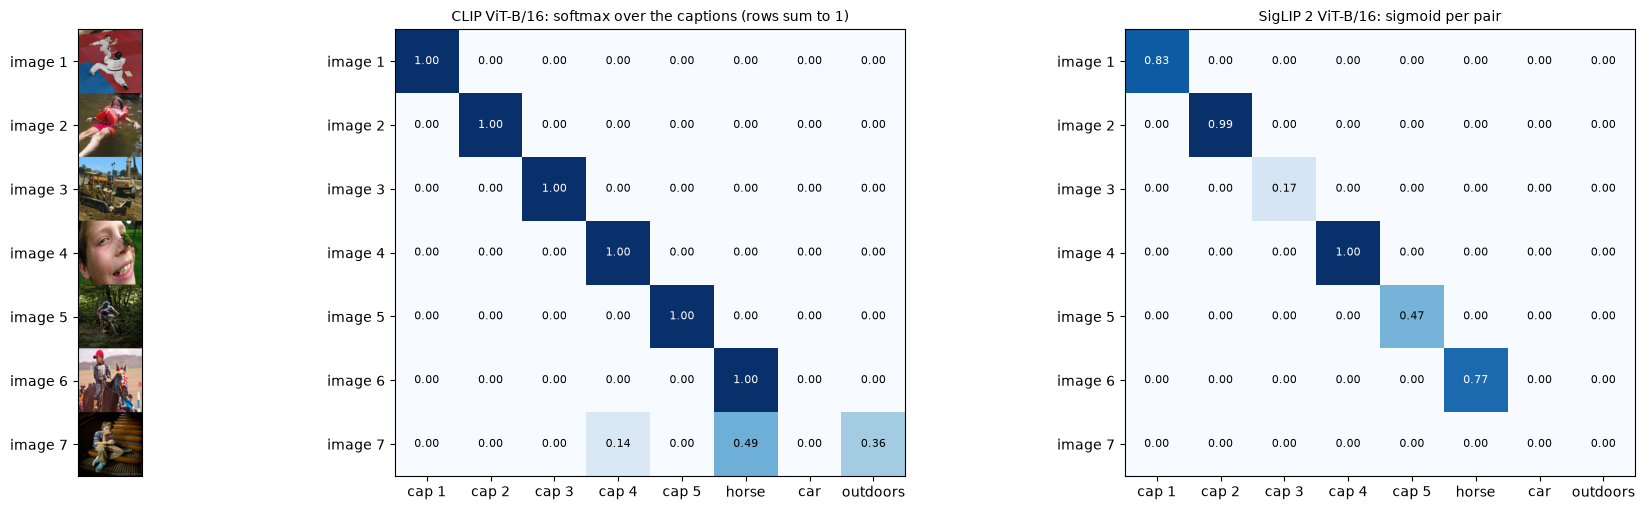

   cap 1: A young female student performing a downward kick to break a board held by her Karate instructor.
   cap 2: A young girl floats on her back in water and peers over her life jacket.
   cap 3: A construction worker is driving heavy equipment at a work site.
   cap 4: Young boy smiles as an extremely large kelly green fly perches on his nose.
   cap 5: A mountain biker travels along a dirt trail inside a heavily wooded area.
   horse: A child on a horse.
     car: A red sports car on a race track.
outdoors: A person outdoors.
learned temperature: CLIP t = 100 | SigLIP 2 t = 112, b = -16.8


In [5]:
from transformers import AutoProcessor

paths, captions = load_flickr30k(DATA_DIR, "test")
demo_ids = [2, 40, 101, 250, 512, 777, 901]
demo_images = [Image.open(paths[i]).convert("RGB") for i in demo_ids]
demo_texts = [captions[i][0] for i in demo_ids[:5]] + ["A child on a horse.", "A red sports car on a race track.",
                                                       "A person outdoors."]
labels = ["cap 1", "cap 2", "cap 3", "cap 4", "cap 5", "horse", "car", "outdoors"]


def pair_scores(repo, images, texts):
    """Returns (similarity logits (images, texts), probabilities the model's loss assigns to them)."""
    model = AutoModel.from_pretrained(repo, dtype=torch.float16).eval().to(DEVICE)
    proc = AutoProcessor.from_pretrained(repo)
    siglip = "siglip" in repo
    kw = dict(padding="max_length", max_length=64) if siglip else dict(padding=True)
    texts = [t.lower() for t in texts] if "siglip2" in repo else texts
    inputs = proc(text=texts, images=images, return_tensors="pt", **kw).to(DEVICE)
    inputs["pixel_values"] = inputs["pixel_values"].half()
    with torch.no_grad():
        logits = model(**inputs).logits_per_image.float().cpu()     # t * cos (+ b for SigLIP)
    probs = torch.sigmoid(logits) if siglip else logits.softmax(dim=1)
    return model, logits, probs


clip_model, clip_logits, clip_probs = pair_scores("openai/clip-vit-base-patch16", demo_images, demo_texts)
siglip_model, siglip_logits, siglip_probs = pair_scores("google/siglip2-base-patch16-224", demo_images, demo_texts)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [0.45, 1, 1]})
axes[0].imshow(np.concatenate([np.asarray(im.resize((120, 120))) for im in demo_images], axis=0))
axes[0].set_yticks(60 + 120 * np.arange(7)); axes[0].set_yticklabels([f"image {i + 1}" for i in range(7)])
axes[0].set_xticks([])
for ax, p, title in [(axes[1], clip_probs, "CLIP ViT-B/16: softmax over the captions (rows sum to 1)"),
                     (axes[2], siglip_probs, "SigLIP 2 ViT-B/16: sigmoid per pair")]:
    ax.imshow(p.numpy(), cmap="Blues", vmin=0, vmax=1)
    for (i, j), v in np.ndenumerate(p.numpy()):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else "black")
    ax.set_xticks(range(8)); ax.set_xticklabels(labels)
    ax.set_yticks(range(7)); ax.set_yticklabels([f"image {i + 1}" for i in range(7)]); ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()
for label, t in zip(labels, demo_texts):
    print(f"{label:>8}: {t}")
print(f"learned temperature: CLIP t = {clip_model.logit_scale.exp().item():.0f} | "
      f"SigLIP 2 t = {siglip_model.logit_scale.exp().item():.0f}, b = {siglip_model.logit_bias.item():.1f}")

<a id='Training'></a>
# Experiment: our own dual encoder on Flickr30k

Training CLIP from scratch needs hundreds of millions of pairs. With 29k images we follow **LiT** (*Locked-image Tuning*, Zhai et al., 2022): take a pretrained image tower, **freeze** it, and train only a text tower (and the projections) to map captions into its feature space. LiT showed that this beats training both towers from scratch even at CLIP scale: the image tower is already good, and the text tower only has to learn to "read" it.

**Setup**

* **Data**: Flickr30k with the standard (Karpathy) split — 29,000 training images, 1,014 validation, 1,000 test; 5 captions per image. One epoch = every training image once with one of its 5 captions picked at random.
* **Image tower** (frozen): DINOv2 ViT-S/14 (with registers) from Lecture 3, [CLS] features at 224 px, computed once for 5 random crops of every training image; a trainable LayerNorm + linear projection to $d = 256$.
* **Text tower** (trained from scratch): 4 transformer blocks of width 256, CLIP's BPE tokenizer, captions up to 32 tokens, mean over the tokens; a linear projection to $d = 256$. 15.8M parameters, 12.6M of them in the token embeddings.
* **Optimization**: AdamW, learning rate $5 \cdot 10^{-4}$, weight decay 0.1, 5% warmup + cosine, **50 epochs**, mixed precision. A run takes 20 seconds to 3 minutes on one GPU.
* **Evaluation**: image-text **retrieval** on the Flickr30k test set (1k images, 5k captions; mean of Recall@1/5/10 in both directions) and **zero-shot classification** of the STL-10 test set — classes our model has never been trained to recognise.

In [6]:
class TextTransformer(nn.Module):
    """A small text encoder trained from scratch: token + position embeddings, pre-norm transformer blocks,
    mean over the non-padding tokens."""

    def __init__(self, vocab_size, max_len=32, width=256, depth=4, heads=4, pad_id=0):
        super().__init__()
        self.pad_id = pad_id
        self.token_embed = nn.Embedding(vocab_size, width)
        self.pos_embed = nn.Parameter(torch.zeros(1, max_len, width))
        layer = nn.TransformerEncoderLayer(width, heads, 4 * width, dropout=0.0, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(width)
        self.width = width
        nn.init.normal_(self.token_embed.weight, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.01)

    def forward(self, tokens):                                              # (B, L) token ids
        pad = tokens == self.pad_id
        x = self.token_embed(tokens) + self.pos_embed[:, :tokens.shape[1]]
        x = self.norm(self.blocks(x, src_key_padding_mask=pad))
        keep = (~pad).unsqueeze(-1).float()
        return (x * keep).sum(1) / keep.sum(1).clamp_min(1)                # (B, width)


class DualEncoder(nn.Module):
    """Image and text towers, each followed by a linear projection into a shared embedding space.

    In the LiT setting ("locked image, unlocked text") the image tower is a frozen pretrained network, so the
    image side receives its pre-computed features and only the projection is trained.
    """

    def __init__(self, image_dim, text_tower, embed_dim=256, loss="siglip"):
        super().__init__()
        assert loss in ("clip", "siglip")
        self.loss_type = loss
        self.image_proj = nn.Sequential(nn.LayerNorm(image_dim), nn.Linear(image_dim, embed_dim))
        self.text_tower = text_tower
        self.text_proj = nn.Linear(text_tower.width, embed_dim)
        if loss == "clip":   # temperature 0.07 as in CLIP
            self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
            self.logit_bias = None
        else:                # SigLIP: t = 10, b = -10, so that at the start almost all pairs are predicted "no match"
            self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
            self.logit_bias = nn.Parameter(torch.tensor(-10.0))

    def encode_image(self, features):
        return F.normalize(self.image_proj(features.float()), dim=-1)

    def encode_text(self, tokens):
        return F.normalize(self.text_proj(self.text_tower(tokens).float()), dim=-1)

    def forward(self, features, tokens):
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=features.is_cuda):
            img, txt = self.encode_image(features), self.encode_text(tokens)
        img, txt = img.float(), txt.float()
        self.logit_scale.data.clamp_(max=math.log(100))                     # as in CLIP
        if self.loss_type == "clip":
            return clip_loss(img, txt, self.logit_scale)
        return siglip_loss(img, txt, self.logit_scale, self.logit_bias)

In [7]:
summary = pd.read_csv(os.path.join(RESULTS_DIR, "summary.csv")).set_index("name")
PRE = os.path.join(RESULTS_DIR, "pretrained")


def load_run(name):
    """One row every 5 epochs: retrieval metrics on the validation set."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}.csv"))


def load_steps(name):
    """~400 rows per run: loss, temperature 1/t and (SigLIP) bias b."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}_steps.csv"))


def seeds_of(name):
    """The run and its repetitions with other seeds."""
    return [n for n in summary.index if n == name or n.startswith(name + "_seed")]


COLUMNS = {"test_mean_recall": "mean recall", "test_i2t_R@1": "image->text R@1", "test_t2i_R@1": "text->image R@1",
           "stl10_zero_shot": "STL-10 zero-shot", "minutes": "minutes"}


def results_table(runs, columns=tuple(COLUMNS)):
    """runs: {run name: label}; mean (and std over seeds where there are several)."""
    rows = {}
    for name, label in runs.items():
        d = summary.loc[seeds_of(name), list(columns)]
        rows[label] = {COLUMNS[c]: (f"{d[c].mean():.3f}" if c == "minutes" else f"{d[c].mean():.1%}") +
                       (f" ± {d[c].std():.1%}" if len(d) > 1 and c != "minutes" else "") for c in columns}
    return pd.DataFrame(rows).T

## Experiment: softmax or sigmoid, and the batch size

Both losses at batch sizes 64, 256, 1024 and 4096, three seeds each. The number of **epochs** is the same (50), so a larger batch means fewer optimizer steps (22,650 steps at batch 64, 350 at 4096) — the trade-off one faces with a fixed dataset and compute.

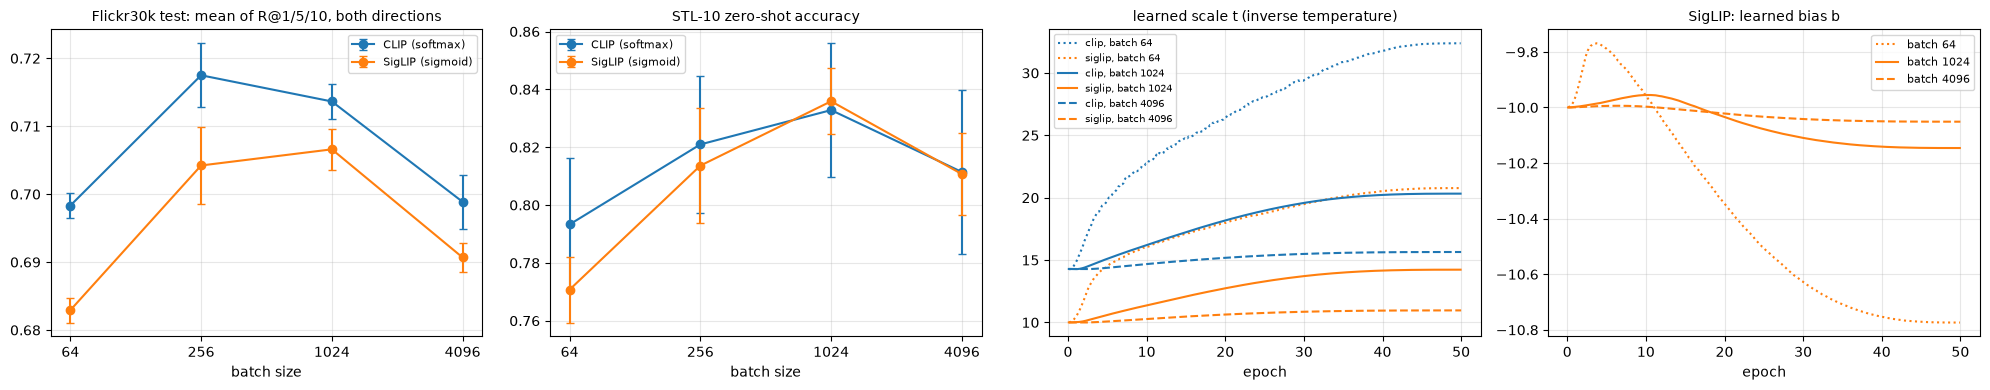

,mean recall,image->text R@1,text->image R@1,STL-10 zero-shot,minutes
"clip, batch 64",69.8% ± 0.2%,52.8% ± 0.7%,40.5% ± 0.7%,79.3% ± 2.3%,3.175
"clip, batch 256",71.8% ± 0.5%,56.8% ± 0.8%,42.6% ± 0.6%,82.1% ± 2.4%,0.863
"clip, batch 1024",71.4% ± 0.3%,58.1% ± 0.8%,42.6% ± 0.4%,83.3% ± 2.3%,0.297
"clip, batch 4096",69.9% ± 0.4%,53.7% ± 1.1%,41.1% ± 0.4%,81.1% ± 2.8%,0.305
"siglip, batch 64",68.3% ± 0.2%,50.8% ± 1.3%,38.3% ± 0.5%,77.1% ± 1.1%,3.297
"siglip, batch 256",70.4% ± 0.6%,54.3% ± 1.0%,41.5% ± 0.4%,81.4% ± 2.0%,0.875
"siglip, batch 1024",70.7% ± 0.3%,56.3% ± 0.6%,42.0% ± 0.5%,83.6% ± 1.1%,0.279
"siglip, batch 4096",69.1% ± 0.2%,54.0% ± 0.6%,39.4% ± 0.5%,81.1% ± 1.4%,0.306


In [8]:
batch_sizes = [64, 256, 1024, 4096]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for loss, color in [("clip", "tab:blue"), ("siglip", "tab:orange")]:
    for ax, col in zip(axes[:2], ["test_mean_recall", "stl10_zero_shot"]):
        vals = [summary.loc[seeds_of(f"{loss}_bs{bs}"), col] for bs in batch_sizes]
        ax.errorbar(batch_sizes, [v.mean() for v in vals], yerr=[v.std() for v in vals], marker="o", capsize=3,
                    color=color, label={"clip": "CLIP (softmax)", "siglip": "SigLIP (sigmoid)"}[loss])
for ax, title in zip(axes[:2], ["Flickr30k test: mean of R@1/5/10, both directions", "STL-10 zero-shot accuracy"]):
    ax.set_xscale("log", base=2); ax.set_xticks(batch_sizes); ax.set_xticklabels(batch_sizes)
    ax.set_xlabel("batch size"); ax.set_title(title, fontsize=10); ax.grid(alpha=0.3); ax.legend(fontsize=8)
for bs, ls in [(64, ":"), (1024, "-"), (4096, "--")]:
    for loss, color in [("clip", "tab:blue"), ("siglip", "tab:orange")]:
        s = load_steps(f"{loss}_bs{bs}")
        axes[2].plot(s.epoch, 1 / s.temperature, color=color, ls=ls, label=f"{loss}, batch {bs}")
    s = load_steps(f"siglip_bs{bs}")
    axes[3].plot(s.epoch, s.bias, color="tab:orange", ls=ls, label=f"batch {bs}")
axes[2].set_title("learned scale t (inverse temperature)", fontsize=10); axes[2].set_xlabel("epoch")
axes[2].legend(fontsize=7); axes[2].grid(alpha=0.3)
axes[3].set_title("SigLIP: learned bias b", fontsize=10); axes[3].set_xlabel("epoch"); axes[3].legend(fontsize=8)
axes[3].grid(alpha=0.3)
plt.tight_layout()
plt.show()
results_table({f"{loss}_bs{bs}": f"{loss}, batch {bs}" for loss in ("clip", "siglip") for bs in batch_sizes})

### Takeaways (softmax vs sigmoid)

* **Softmax beats sigmoid here, at every batch size.** On Flickr30k retrieval the CLIP loss is 0.7–1.5 points of mean recall ahead of SigLIP at every batch size, more than the spread over seeds (≤ 0.6). On STL-10 zero-shot the two are equal within noise (seed std 1–3 points). **The paper's result — sigmoid better at small batches — is not reproduced** in this setting. Our regime is very different: a 29k-image dataset seen 50 times, a frozen image tower, and SigLIP's initialisation ($t = 10$, $b = -10$) designed for batches of 32k on billions of pairs. The practical advantage of SigLIP — memory and communication at large scale — does not show up on one GPU.
* **Both losses have the same optimum, batch 256–1024.** Batch 64 gives 22,650 noisy steps with few negatives; batch 4096 gives only 350 steps and does not converge in 50 epochs. With a fixed dataset, batch size trades negatives against the number of updates — "larger is better" holds only when the number of steps grows with it.
* **The temperature adapts to the batch size.** The learned scale $t$ ends at 32 (CLIP) and 21 (SigLIP) at batch 64, 20 and 14 at batch 1024, 16 and 11 at batch 4096 — far below the 100–117 of the web-scale models. With few negatives, the model sharpens the similarities to make each one count. The SigLIP bias stays close to its initial $-10$ (between $-10.8$ and $-10.0$).
* The zero-shot accuracy on STL-10 varies by up to 5 points between seeds of the same configuration (e.g. 78–82% for CLIP at batch 64), while retrieval varies by about one point at most: **evaluate zero-shot transfer with several seeds or several datasets** before drawing conclusions.

## Experiment: what the frozen image tower brings

All with the SigLIP loss, batch 1024, 50 epochs; only the frozen image tower changes. The last row keeps DINOv2 but replaces our text tower by a **pretrained** sentence encoder (MiniLM-L6, 22M parameters, fine-tuned with a 10× smaller learning rate). The second plot uses fewer training images (the same number of optimizer steps, batch 256).

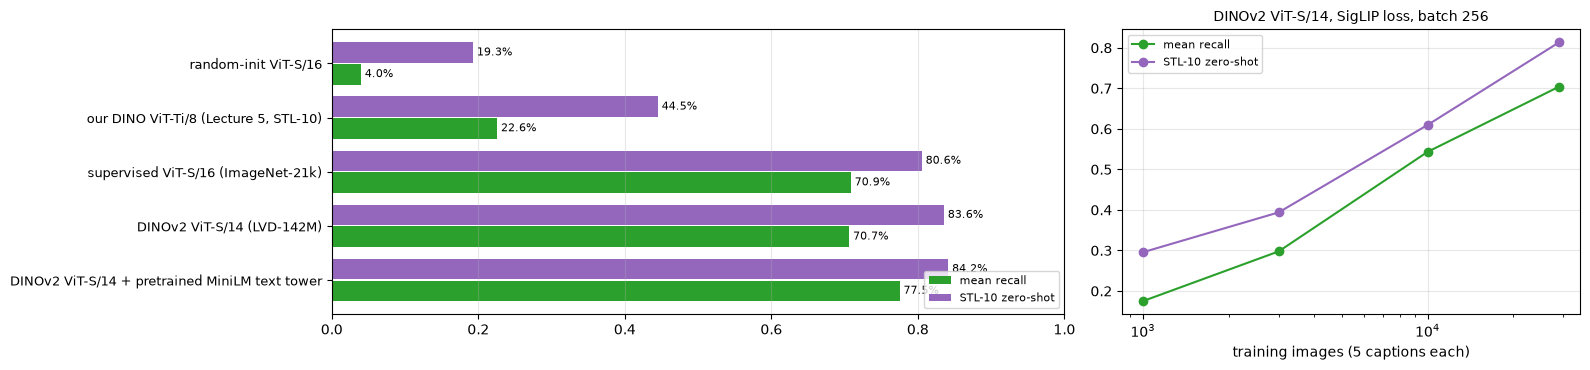

,mean recall,image->text R@1,text->image R@1,STL-10 zero-shot,minutes
random-init ViT-S/16,4.0%,0.9%,1.2%,19.3%,0.278
"our DINO ViT-Ti/8 (Lecture 5, STL-10)",22.6%,9.0%,7.9%,44.5%,0.282
supervised ViT-S/16 (ImageNet-21k),70.9%,56.1%,40.8%,80.6%,0.283
DINOv2 ViT-S/14 (LVD-142M),70.7% ± 0.3%,56.3% ± 0.6%,42.0% ± 0.5%,83.6% ± 1.1%,0.279
DINOv2 ViT-S/14 + pretrained MiniLM text tower,77.5%,64.8%,49.4%,84.2%,0.641
"1,000 training images",17.5%,9.3%,6.2%,29.6%,0.864
"3,000 training images",29.8%,15.7%,10.4%,39.4%,0.862
"10,000 training images",54.3%,38.2%,25.2%,61.0%,0.862
"29,000 training images",70.4% ± 0.6%,54.3% ± 1.0%,41.5% ± 0.4%,81.4% ± 2.0%,0.875


In [9]:
towers = {"tower_random_vits16": "random-init ViT-S/16", "tower_lecture5_dino_vitti8": "our DINO ViT-Ti/8 (Lecture 5, STL-10)",
          "tower_sup_vits16_in21k": "supervised ViT-S/16 (ImageNet-21k)", "siglip_bs1024": "DINOv2 ViT-S/14 (LVD-142M)",
          "text_minilm": "DINOv2 ViT-S/14 + pretrained MiniLM text tower"}
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
y = np.arange(len(towers))
for k, (col, color) in enumerate([("test_mean_recall", "tab:green"), ("stl10_zero_shot", "tab:purple")]):
    vals = [summary.loc[seeds_of(n), col].mean() for n in towers]
    axes[0].barh(y + 0.2 - 0.4 * k, vals, height=0.38, color=color, label=COLUMNS[col])
    for yi, v in zip(y + 0.2 - 0.4 * k, vals):
        axes[0].text(v + 0.005, yi, f"{v:.1%}", va="center", fontsize=8)
axes[0].set_yticks(y); axes[0].set_yticklabels(towers.values(), fontsize=9); axes[0].invert_yaxis()
axes[0].set_xlim(0, 1); axes[0].legend(fontsize=8, loc="lower right"); axes[0].grid(alpha=0.3, axis="x")
data_runs = {1000: "data_1k", 3000: "data_3k", 10000: "data_10k", 29000: "siglip_bs256"}
for col, color in [("test_mean_recall", "tab:green"), ("stl10_zero_shot", "tab:purple")]:
    axes[1].plot(list(data_runs), [summary.loc[seeds_of(n), col].mean() for n in data_runs.values()], "o-",
                 color=color, label=COLUMNS[col])
axes[1].set_xscale("log"); axes[1].set_xlabel("training images (5 captions each)"); axes[1].grid(alpha=0.3)
axes[1].set_title("DINOv2 ViT-S/14, SigLIP loss, batch 256", fontsize=10); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
results_table({**towers, **{v: f"{k:,} training images" for k, v in data_runs.items()}})

### Takeaways (image tower and data)

* **The image tower decides almost everything.** With the same text tower and loss, a random-init ViT gives 4.0% mean recall, our Lecture 5 DINO ViT-Ti/8 (5M parameters, trained on 100k STL-10 images at 96 px) 22.6%, supervised ImageNet-21k ViT-S/16 70.9%, DINOv2 ViT-S/14 70.7%. The text tower can only learn to name what the image features already separate.
* **Supervised ImageNet-21k and DINOv2 are equal for retrieval** (70.9% vs 70.7%), DINOv2 is 3 points better zero-shot on STL-10. 21k classes of labels are already close to "language" supervision; LiT itself found supervised ImageNet-21k towers to work very well.
* **Even our small Lecture 5 model transfers**: 44.5% zero-shot on STL-10 (chance 10%) from captions of Flickr photos, which are mostly about people. Its features were learned on STL-10 itself, so this is not a fair test of generality — but it shows that self-supervised features can be "connected to language" afterwards with a few thousand captions.
* **A pretrained text tower helps** (MiniLM: +6.8 points of mean recall, 77.5%), less for zero-shot on STL-10 (+0.6). A frozen pretrained image tower + a pretrained text tower is the cheapest way to a working dual encoder.
* **Data: no saturation.** Mean recall goes 17.5% → 29.8% → 54.3% → 70.4% for 1k → 3k → 10k → 29k images, roughly linear in the log of the dataset size, with the same number of steps. This is the reason CLIP-style models are trained on hundreds of millions to billions of pairs.

<a id='ZeroShot'></a>
# Zero-shot classification

A classifier needs one weight vector per class. A dual encoder can produce it from the **class name**: embed a prompt such as *"a photo of a dog."* with the text tower and classify an image by its most similar prompt. No training image of the target dataset is used — the "classifier" is written in natural language. CLIP-style prompt **ensembling** averages the text embeddings of several prompts per class ("a photo of a {}.", "a blurry photo of a {}.", "art of the {}.", ...), and dataset-specific prompts tell the text tower what kind of name follows ("a photo of a {}, a type of pet.").

In [10]:
@torch.no_grad()
def zero_shot_weights(encode_text, classnames, templates=("a photo of a {}.",)):
    """One "classifier weight" per class: the mean of the normalized text embeddings of its prompts.

    encode_text: list of strings -> (N, D) L2-normalized embeddings.
    """
    weights = []
    for name in classnames:
        emb = encode_text([t.format(name) for t in templates])
        weights.append(F.normalize(emb.float().mean(0), dim=-1))
    return torch.stack(weights)                                             # (C, D)


@torch.no_grad()
def zero_shot_accuracy(image_emb, labels, class_weights):
    return ((image_emb.float() @ class_weights.T).argmax(1) == labels).float().mean().item()

We evaluate the three pretrained models (CLIP ViT-B/16 on 400M pairs, SigLIP ViT-B/16 and SigLIP 2 ViT-B/16 on WebLI, 10B images) on STL-10 and on the three fine-grained datasets of Lecture 3: Oxford-IIIT **Pets** (37 breeds), Oxford **Flowers**-102 and **DTD** (47 textures). Our own LiT models are evaluated on STL-10 only — Flickr30k captions rarely name a dog breed, a flower species or a texture.

STL-10, 'a photo of a {}.':  our LiT (DINOv2 + text from scratch), clip: 83.3% | our LiT (DINOv2 + text from scratch), siglip: 83.6%


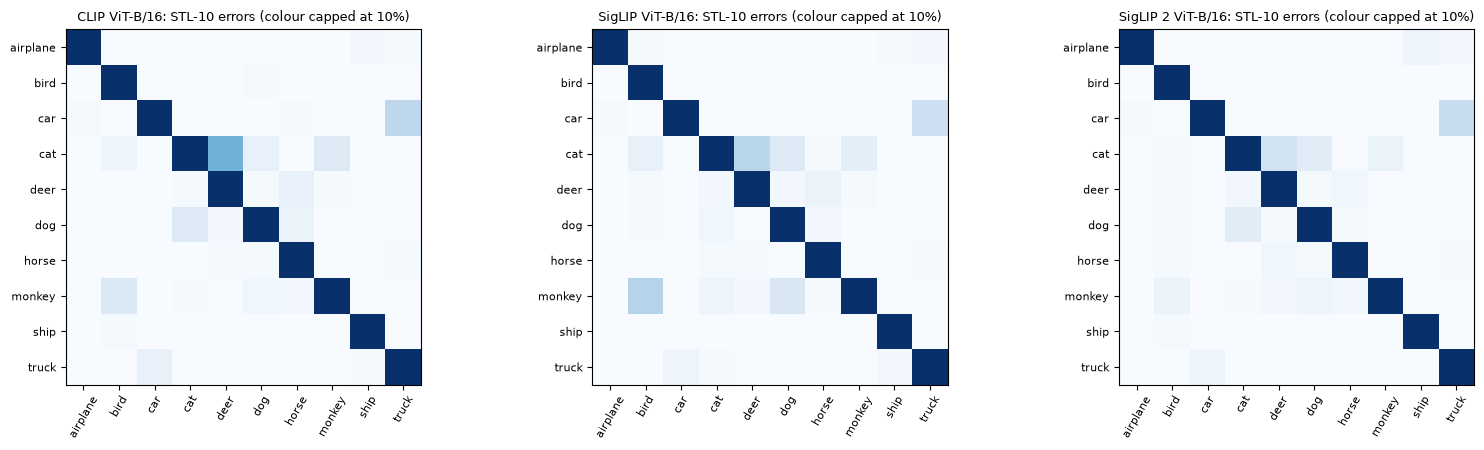

In [11]:
zs = pd.read_csv(os.path.join(PRE, "zero_shot.csv"))
table = zs.pivot_table(index=["dataset", "prompts"], columns="model", values="acc", sort=False)
ours = {f"our LiT (DINOv2 + text from scratch), {loss}": summary.loc[seeds_of(f"{loss}_bs1024"), "stl10_zero_shot"].mean()
        for loss in ("clip", "siglip")}
display(table.style.format("{:.1%}").background_gradient(cmap="Greens", axis=None))
print("STL-10, 'a photo of a {}.':  " + " | ".join(f"{k}: {v:.1%}" for k, v in ours.items()))

geo = np.load(os.path.join(PRE, "geometry.npz"))
models = ["CLIP ViT-B/16", "SigLIP ViT-B/16", "SigLIP 2 ViT-B/16"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, m in zip(axes, models):
    conf = geo[f"{m}|confusion"]
    conf = conf / conf.sum(1, keepdims=True)
    ax.imshow(conf, cmap="Blues", vmin=0, vmax=0.1)
    ax.set_xticks(range(10)); ax.set_xticklabels(STL10_CLASSES, rotation=60, fontsize=8)
    ax.set_yticks(range(10)); ax.set_yticklabels(STL10_CLASSES, fontsize=8)
    ax.set_title(f"{m}: STL-10 errors (colour capped at 10%)", fontsize=9)
plt.tight_layout()
plt.show()

### Takeaways (zero-shot)

* **STL-10 is solved zero-shot**: 98.4–98.8% for all three pretrained models, without a single STL-10 training image (the supervised ResNet-18 of Lecture 4 needed 5k labels for 82%). The remaining errors are semantic neighbours: cat → deer (5% of cats for CLIP), monkey → bird, car → truck.
* **On fine-grained datasets the models differ much more**: Pets 89% (CLIP) vs 95% (SigLIP 2), Flowers 71% vs 84–85%, DTD 45% vs 64–67%. SigLIP / SigLIP 2 were trained on WebLI (10B images) and CLIP on 400M pairs: the gain comes as much from the data as from the loss.
* **Prompts matter, most for the weakest model.** For CLIP on Pets: class name alone 81.7%, "a photo of a {}." 88.1%, "a photo of a {}, a type of pet." 89.1%; on Flowers 63.8% → 71.3%. For SigLIP 2 the differences shrink to 0–4 points — and are not always positive (Flowers: the class name alone is best). On STL-10 the 16-prompt ensemble gives nothing over one good prompt.
* **Textures are the hardest**: DTD names ("banded", "crosshatched", "fibrous") are rare in captions, and zero-shot accuracy there is 19 points below the linear probe even for SigLIP 2. Zero-shot works as well as the class names are represented in the pre-training text.
* Our own LiT models reach 83.3–83.6% on STL-10 from 29k Flickr images — about 15 points below the web-scale models, with a frozen DINOv2 ViT-S.

<a id='Retrieval'></a>
# Image-text retrieval and the shared embedding space

**Retrieval** uses the joint space directly: for a caption, rank all images by cosine similarity (text → image), or rank all captions for an image (image → text). Recall@K is the fraction of queries whose correct match is among the top $K$. On Flickr30k each image has 5 correct captions; image → text counts a hit if any of them is in the top $K$.

In [12]:
@torch.no_grad()
def retrieval_metrics(image_emb, text_emb, text_to_image, ks=(1, 5, 10)):
    """image_emb (Ni, D), text_emb (Nt, D) normalized; text_to_image (Nt,) index of the image of each caption.

    Image -> text: an image is a hit at k if any of its captions is among the k most similar captions.
    Text -> image: a caption is a hit at k if its image is among the k most similar images.
    """
    sims = image_emb.float() @ text_emb.float().T                           # (Ni, Nt)
    correct = text_to_image[None, :] == torch.arange(len(image_emb), device=sims.device)[:, None]
    # rank of the best correct caption of every image = number of captions scored above it
    best = sims.masked_fill(~correct, -float("inf")).max(1).values
    i2t_rank = (sims > best[:, None]).sum(1)
    # rank of the correct image of every caption
    t2i_rank = (sims.T > sims.T.gather(1, text_to_image[:, None])).sum(1)
    out = {}
    for k in ks:
        out[f"i2t_R@{k}"] = (i2t_rank < k).float().mean().item()
        out[f"t2i_R@{k}"] = (t2i_rank < k).float().mean().item()
    out["mean_recall"] = sum(out.values()) / len(out)
    return out

,i2t_R@1,i2t_R@5,i2t_R@10,t2i_R@1,t2i_R@5,t2i_R@10,mean_recall
model,,,,,,,
CLIP ViT-B/16,82.3%,96.7%,99.0%,62.2%,85.6%,92.0%,86.3%
SigLIP ViT-B/16,89.1%,98.0%,99.3%,74.6%,92.3%,95.6%,91.5%
SigLIP 2 ViT-B/16,91.8%,98.8%,99.6%,78.5%,93.9%,96.7%,93.2%
"our LiT, CLIP loss",58.1%,83.5%,90.9%,42.6%,72.1%,81.0%,71.4%
"our LiT, SigLIP loss",56.3%,82.9%,90.7%,42.0%,71.7%,80.3%,70.7%
"our LiT, SigLIP loss + MiniLM text tower",64.8%,89.5%,94.4%,49.4%,80.0%,87.1%,77.5%


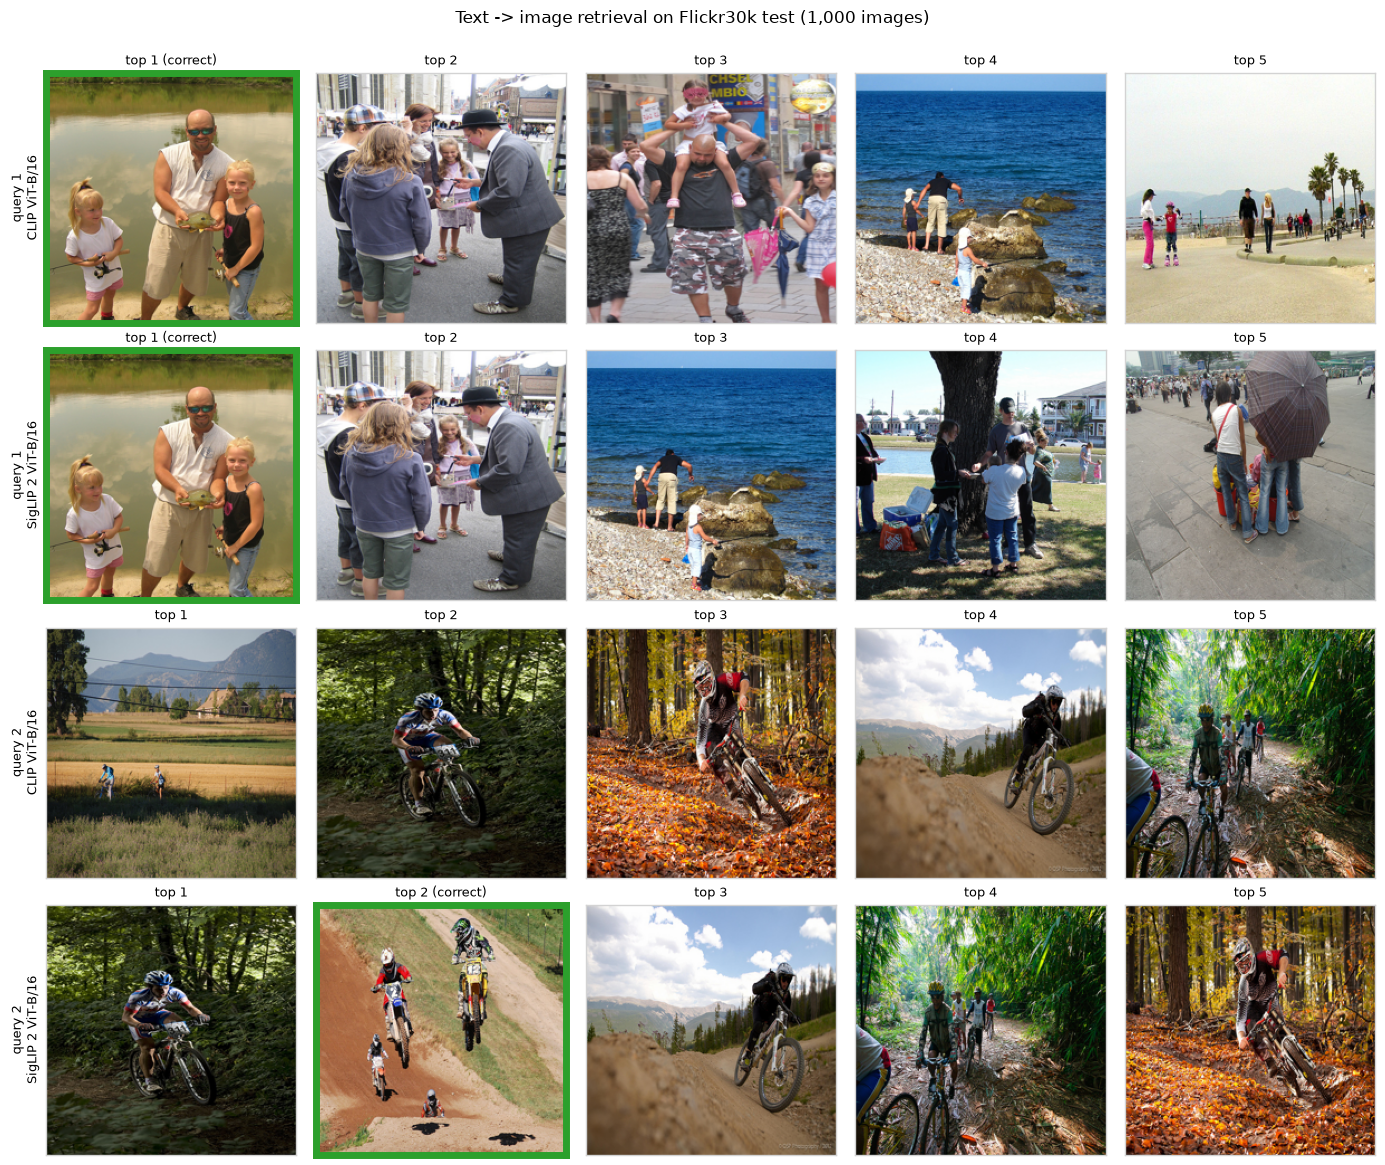

query 1: This man holds a fish while two little girls stand to either side of him.
query 2: A group of mountain bikers race each other down a dirt hill.


In [13]:
ret = pd.read_csv(os.path.join(PRE, "retrieval.csv")).set_index("model")
for name, label in [("clip_bs1024", "our LiT, CLIP loss"), ("siglip_bs1024", "our LiT, SigLIP loss"),
                    ("text_minilm", "our LiT, SigLIP loss + MiniLM text tower")]:
    ret.loc[label] = summary.loc[seeds_of(name), [f"test_{c}" for c in ret.columns]].mean().values
cols = ["i2t_R@1", "i2t_R@5", "i2t_R@10", "t2i_R@1", "t2i_R@5", "t2i_R@10", "mean_recall"]
display(ret[cols].style.format("{:.1%}").background_gradient(cmap="Greens", axis=0))

examples = json.load(open(os.path.join(PRE, "examples.json")))
flat_caps = [c for caps in captions for c in caps]
fig, axes = plt.subplots(4, 5, figsize=(14, 11.6))
for r, (k, m) in enumerate([(k, m) for k in range(2) for m in ("CLIP ViT-B/16", "SigLIP 2 ViT-B/16")]):
    q = examples["query_captions"][k]
    for j, img_id in enumerate(examples[m]["caption_to_images"][k]):
        ax = axes[r, j]
        ax.imshow(Image.open(paths[img_id]).convert("RGB").resize((224, 224)))
        hit = img_id == q // 5                              # 5 captions per image, in order
        for s in ax.spines.values():
            s.set_edgecolor("tab:green" if hit else "lightgray"); s.set_linewidth(5 if hit else 1)
        ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"top {j + 1}" + (" (correct)" if hit else ""), fontsize=9)
    axes[r, 0].set_ylabel(f"query {k + 1}\n{m}", fontsize=9)
plt.suptitle("Text -> image retrieval on Flickr30k test (1,000 images)", y=1.0)
plt.tight_layout()
plt.show()
for k in range(2):
    print(f"query {k + 1}: {flat_caps[examples['query_captions'][k]]}")

**The shared embedding space.** Image and text embeddings live on the same sphere, but they do not mix: Liang et al. (2022) found that in CLIP the two modalities occupy two separate narrow cones — the **modality gap**. It appears already at initialisation (each randomly initialised tower maps all its inputs into a narrow cone) and the contrastive loss with a low temperature preserves it. Below: cosine similarities on the 1,000 Flickr30k test pairs, and a shared 2D PCA of the image and text embeddings.

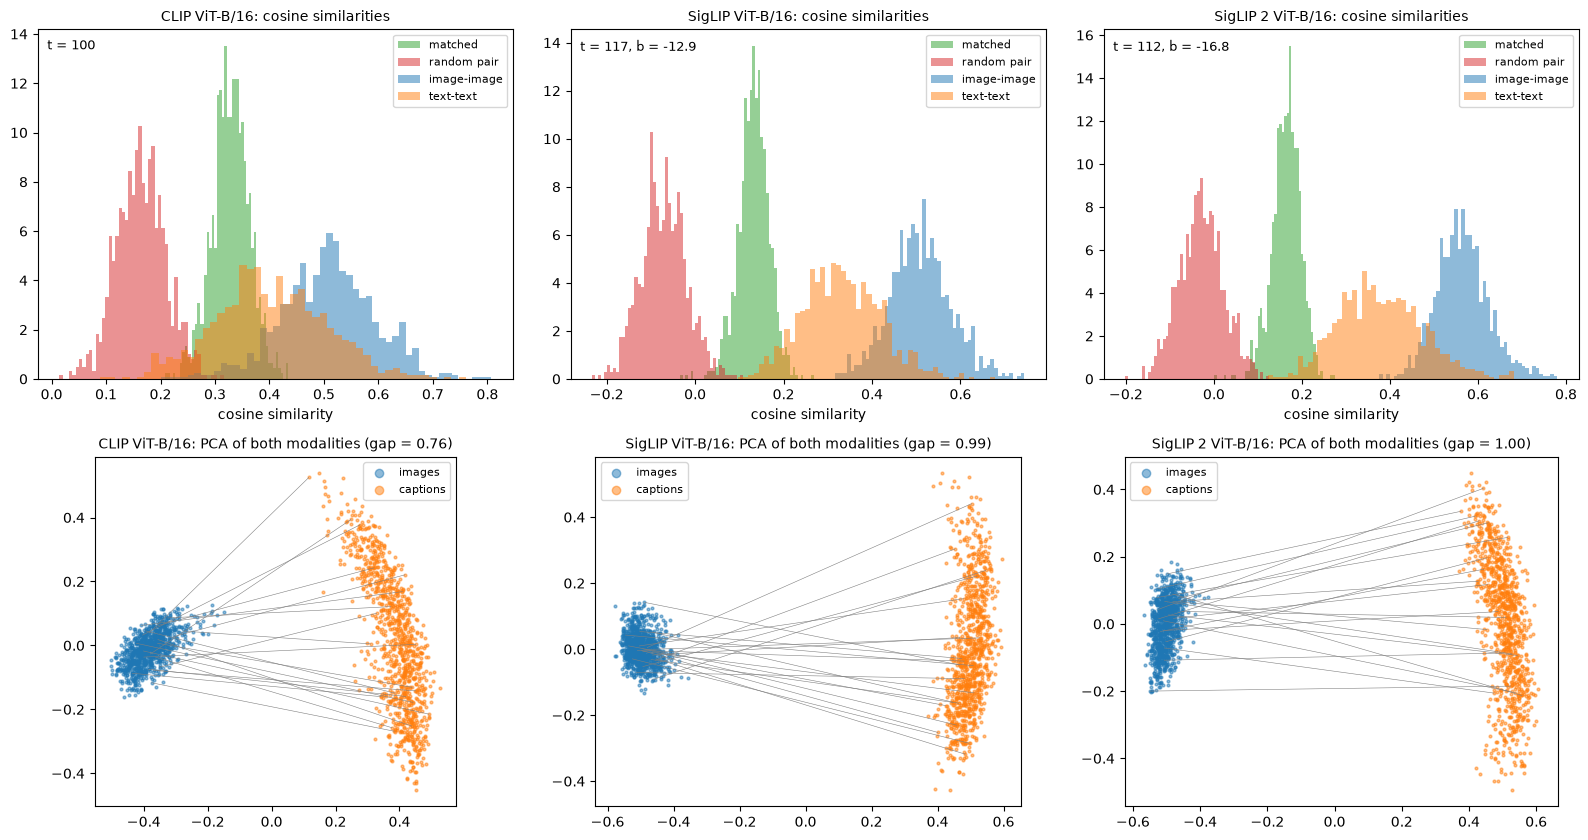

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for k, m in enumerate(models):
    ax = axes[0, k]
    for stat, color in [("matched", "tab:green"), ("random pair", "tab:red"), ("image-image", "tab:blue"),
                        ("text-text", "tab:orange")]:
        ax.hist(geo[f"{m}|cos|{stat}"], bins=50, alpha=0.5, color=color, label=stat, density=True)
    ax.set_title(f"{m}: cosine similarities", fontsize=10); ax.set_xlabel("cosine similarity"); ax.legend(fontsize=8)
    scale = float(geo[f"{m}|logit_scale"])
    bias = f", b = {float(geo[f'{m}|logit_bias']):.1f}" if f"{m}|logit_bias" in geo.files else ""
    ax.text(0.02, 0.97, f"t = {scale:.0f}{bias}", transform=ax.transAxes, va="top", fontsize=9)
    pca = geo[f"{m}|pca"]
    axes[1, k].scatter(*pca[:1000].T, s=4, alpha=0.5, label="images")
    axes[1, k].scatter(*pca[1000:].T, s=4, alpha=0.5, label="captions")
    for i in range(0, 1000, 50):    # a few matched pairs
        axes[1, k].plot([pca[i, 0], pca[1000 + i, 0]], [pca[i, 1], pca[1000 + i, 1]], color="gray", lw=0.4)
    axes[1, k].set_title(f"{m}: PCA of both modalities (gap = {float(geo[f'{m}|gap']):.2f})", fontsize=10)
    axes[1, k].legend(fontsize=8, markerscale=3); axes[1, k].set_aspect("equal")
plt.tight_layout()
plt.show()

### Takeaways (retrieval and the embedding space)

* **SigLIP 2 > SigLIP > CLIP** on Flickr30k: mean recall 93.2% / 91.5% / 86.3%; text → image R@1 78.5% / 74.6% / 62.2%. The models are of the same size (ViT-B/16), so the difference is the data and the training recipe.
* **Our LiT models are far behind** (71–78% mean recall) — they were trained on 29k images, the pretrained ones on 400M–10B. Even so, the right image is in the top 10 for 80–87% of the captions. Text → image is always harder than image → text, because an image has 5 chances (captions) to be found.
* **Many retrieval "errors" are near misses or caption noise.** The wrongly ranked images share the scene (groups of people with children; riders on bikes in a forest). In query 2 the "correct" image shows *motocross* riders, while the caption says mountain bikers: CLIP ranks five real mountain-bike photos above it, which is arguably the right answer. Recall@1 on Flickr30k is limited by the captions as much as by the model.
* **The modality gap is large in all three models.** In the PCA, images and captions form two separate clusters; in cosine similarity, two random images (0.5–0.57 on average) or two random captions (0.33–0.40) are more similar than an image and its own caption (0.13–0.33). **The nearest neighbour of an image is almost always another image**, not a caption. Retrieval still works because only the *ranking* of captions for one image matters, and the matched caption is clearly above the random ones (0.33 vs 0.16 for CLIP, 0.13–0.16 vs −0.07–−0.03 for SigLIP).
* The gap is larger for SigLIP and SigLIP 2 (distance between the means 0.99–1.00) than for CLIP (0.76): the sigmoid loss with a large negative bias only needs matched pairs to be above a threshold, not close.

<a id='Transfer'></a>
# Transfer to downstream tasks

How good are image-text features as **general visual features**? Three ways to use them on a new labeled dataset, with the image tower frozen:

* **zero-shot**: no labeled images, only class names;
* **few-shot linear probe**: logistic regression on $k$ labeled images per class (5 random draws);
* **linear probe** on all labeled training images (Lecture 3 protocol), and the same probe on **DINOv2 ViT-B/14** — the vision-only reference of the same size.

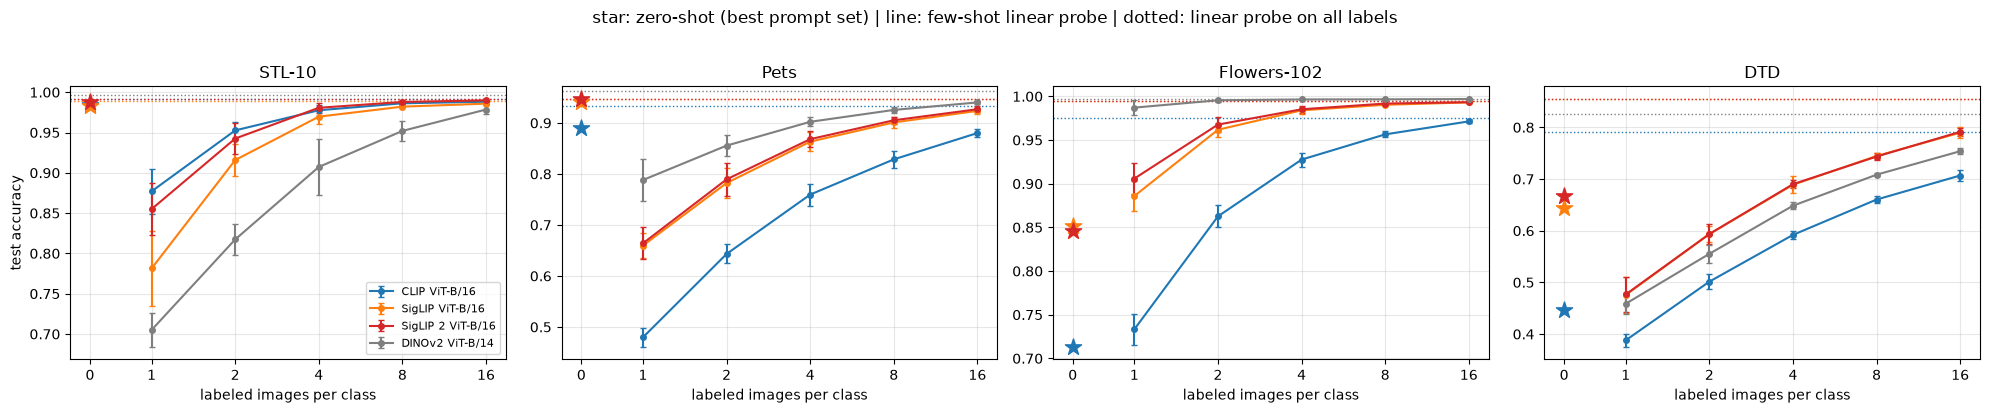

In [15]:
pr = pd.read_csv(os.path.join(PRE, "probes.csv"))
datasets = {"stl10": "STL-10", "pets": "Pets", "flowers": "Flowers-102", "dtd": "DTD"}
colors = {"CLIP ViT-B/16": "tab:blue", "SigLIP ViT-B/16": "tab:orange", "SigLIP 2 ViT-B/16": "tab:red",
          "DINOv2 ViT-B/14": "tab:gray"}
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (ds, title) in zip(axes, datasets.items()):
    for m, color in colors.items():
        d = pr[(pr.model == m) & (pr.dataset == ds)]
        fs = d[d.protocol == "few-shot linear"].groupby("shots").acc
        ax.errorbar(fs.mean().index, fs.mean(), yerr=fs.std(), marker="o", ms=4, capsize=2, color=color, label=m)
        ax.axhline(d[d.protocol == "linear (all labels)"].acc.item(), color=color, ls=":", lw=1)
        if m in models:
            best_zs = zs[(zs.model == m) & (zs.dataset == ds)].acc.max()
            ax.scatter([0.6], [best_zs], marker="*", s=150, color=color, zorder=3)
    ax.set_xscale("log", base=2); ax.set_xticks([0.6, 1, 2, 4, 8, 16]); ax.set_xticklabels(["0", 1, 2, 4, 8, 16])
    ax.set_xlabel("labeled images per class"); ax.set_title(title); ax.grid(alpha=0.3)
axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=8)
plt.suptitle("star: zero-shot (best prompt set) | line: few-shot linear probe | dotted: linear probe on all labels", y=1.02)
plt.tight_layout()
plt.show()
lin = pr[pr.protocol == "linear (all labels)"].pivot_table(index="model", columns="dataset", values="acc")
zsb = zs.groupby(["model", "dataset"]).acc.max().unstack()
display(pd.concat({"zero-shot (best prompts)": zsb, "linear probe (all labels)": lin}, axis=1)
        .reindex(columns=list(datasets), level=1).style.format("{:.1%}", na_rep="—"))

**Dense features.** A VLM receives the **patch tokens**, not the pooled embedding, so their quality matters as much. As in Lecture 5, we project the patch tokens of an image onto their first 3 principal components and show them as RGB (here the PCA is computed **per image**, so colours are not comparable across images). All three models see a $32 \times 32$ grid of patches: SigLIP 2 at 512 px (the nanoVLM checkpoint loaded into our ViT above), CLIP at 512 px (positional embeddings interpolated), DINOv2 at 448 px.

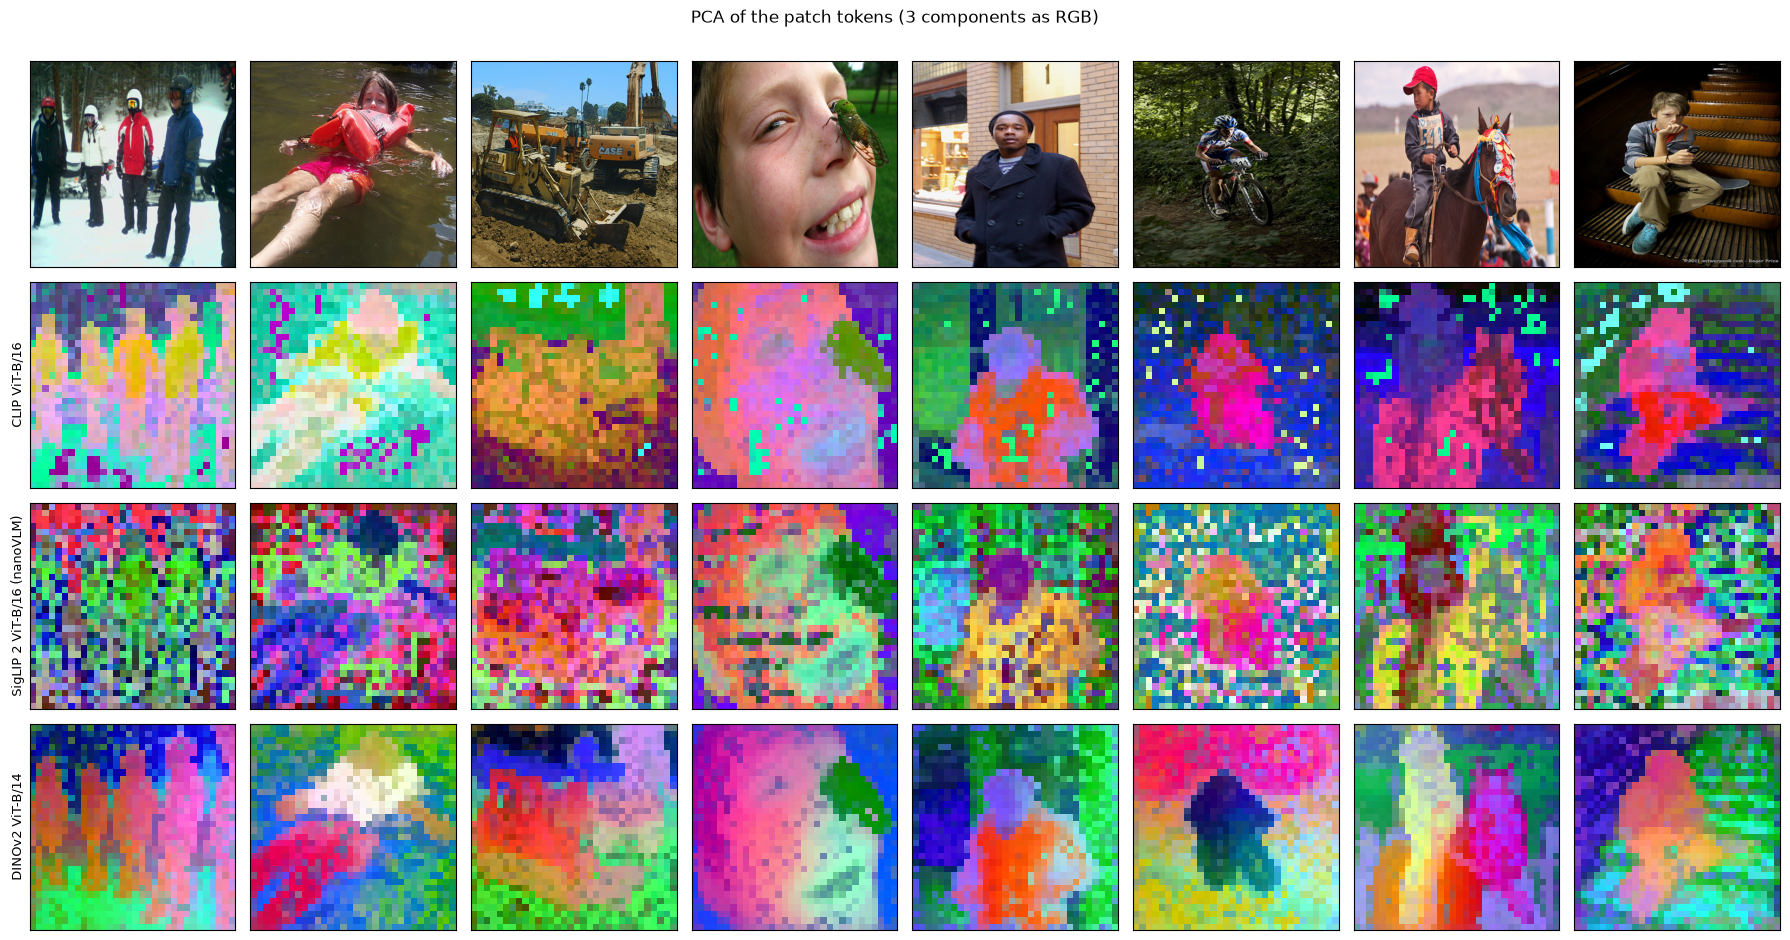

In [16]:
@torch.no_grad()
def patch_pca(tokens):
    """tokens: (B, N, D) patch tokens -> (B, sqrt(N), sqrt(N), 3): the first 3 principal components of every image
    as RGB in [0, 1]."""
    B, N, D = tokens.shape
    g = int(math.isqrt(N))
    out = []
    for x in tokens.float():
        x = x - x.mean(0)
        with torch.autocast(x.device.type, enabled=False):
            _, _, v = torch.pca_lowrank(x, q=3, center=False)
            rgb = x @ v
        lo, hi = rgb.quantile(0.01, dim=0), rgb.quantile(0.99, dim=0)
        out.append(((rgb - lo) / (hi - lo)).clamp(0, 1).reshape(g, g, 3))
    return torch.stack(out).cpu().numpy()


pca_images = [Image.open(paths[i]).convert("RGB") for i in [3, 40, 101, 250, 404, 512, 777, 901]]
to_tensor = lambda im, size, mean, std: ((torch.tensor(np.asarray(im.resize((size, size), Image.BICUBIC)),
                                                       dtype=torch.float32) / 255 - torch.tensor(mean)) /
                                         torch.tensor(std)).permute(2, 0, 1)
batch = lambda size, mean, std: torch.stack([to_tensor(im, size, mean, std) for im in pca_images]).to(DEVICE)
pictures = {}
with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16, enabled=DEVICE == "cuda"):
    out = clip_model.vision_model(pixel_values=batch(512, (0.481, 0.458, 0.408), (0.269, 0.261, 0.276)).half(),
                                  interpolate_pos_encoding=True).last_hidden_state
    pictures["CLIP ViT-B/16"] = patch_pca(clip_model.vision_model.post_layernorm(out)[:, 1:])
    pictures["SigLIP 2 ViT-B/16 (nanoVLM)"] = patch_pca(vit.forward_features(batch(512, (0.5,) * 3, (0.5,) * 3)))
    dinov2 = timm.create_model("vit_base_patch14_reg4_dinov2.lvd142m", pretrained=True, num_classes=0,
                               img_size=448).eval().to(DEVICE)
    out = dinov2.forward_features(batch(448, (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)))
    pictures["DINOv2 ViT-B/14"] = patch_pca(out[:, dinov2.num_prefix_tokens:])
fig, axes = plt.subplots(4, 8, figsize=(18, 9.4))
for i, im in enumerate(pca_images):
    axes[0, i].imshow(im.resize((448, 448)))
for row, (name, rgb) in enumerate(pictures.items(), start=1):
    for i in range(8):
        axes[row, i].imshow(rgb[i])
    axes[row, 0].set_ylabel(name, fontsize=9)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("PCA of the patch tokens (3 components as RGB)", y=1.0)
plt.tight_layout()
plt.show()

### Takeaways (transfer)

* **Zero-shot ≈ few-shot.** For CLIP, zero-shot equals a linear probe on about 16 images per class on Pets, 1 on Flowers, 1–2 on DTD; for SigLIP 2, it is better than 16-shot on Pets and close to 4-shot on DTD. A text prompt is worth from one to more than sixteen labeled images per class, depending on how well the class names are represented in the pre-training captions — the CLIP paper's observation.
* **With all labels, image-text features are as good as DINOv2 for classification.** Linear probes: SigLIP / SigLIP 2 are the best on DTD (85.5% vs 82.7% for DINOv2 ViT-B/14), DINOv2 is the best on Pets (96.3% vs 94.7%) and on STL-10; Flowers is saturated (99.4–99.7%). CLIP ViT-B/16 is the weakest of the four on every dataset (e.g. Flowers 97.5%, Pets 93.3%).
* **k-NN tells a different story** — CLIP's k-NN on Pets is 83.7% vs 94.2% for DINOv2: language-aligned features are linearly separable but their neighbourhoods are less clean.
* **Dense features: DINOv2 is clearly ahead.** Its patch tokens separate people, faces and objects into parts, with sharp boundaries. CLIP separates the main object from the background, with scattered **high-norm artifact tokens** (the isolated patches of a different colour) — the effect that motivated register tokens (Lecture 5). The last-layer tokens of SigLIP 2 are the noisiest in this picture, although its dense objectives improve dense *probes* in the paper. A pooled-embedding objective does not require the patch tokens to be locally meaningful — the reason why SigLIP 2 added DINO-style objectives and why Cambrian-1 combines CLIP-style and DINOv2 encoders for VLMs.

## Where it goes from here

* **Better data instead of a better loss.** Most progress after CLIP came from the data: MetaCLIP re-creates CLIP's data curation in the open, DFN trains a network to filter image-text pairs, SigLIP 2 adds active data curation for the small models.
* **More objectives in one encoder.** CoCa adds a captioning decoder to the contrastive loss; SigLIP 2 adds captioning, self-distillation and masked prediction; Perception Encoder shows that the best features for a VLM are often in the *intermediate* layers of a contrastive model and aligns them to the output.
* **Dense and open-vocabulary tasks.** OWL-ViT / OWLv2 turn a CLIP-style model into an open-vocabulary detector (every patch token gets a box and an embedding compared to text queries); open-vocabulary segmentation does the same per pixel. These are exactly the tasks where the poor patch features of plain CLIP hurt.
* **Encoders for VLMs.** Higher resolution and native aspect ratio (SigLIP 2 NaFlex, Qwen-VL), several encoders combined (Cambrian), or language-free encoders scaled up (Web-SSL): which pre-training gives the best *eye* for a language model is an open question.

**When to use which (2025):**
* Zero-shot classification, retrieval, filtering of a dataset by text: a pretrained **SigLIP 2** (or CLIP) model, used as is.
* A small VLM: **SigLIP 2** as the vision encoder (nanoVLM, SmolVLM); add **DINOv2/v3** features if the task is spatial.
* Your own image-text data in a new domain: **LiT** — a frozen strong image tower and a text tower trained on your pairs, with the **sigmoid** loss if the batch is small.

<a id='Summary'></a>
# Summary

* A **dual encoder** maps images and texts into one embedding space. **CLIP** trains it with the symmetric InfoNCE loss of Lecture 4 — the other captions of the batch are the negatives; **SigLIP** replaces the softmax by an independent sigmoid per pair with a learned bias.
* The joint space gives **zero-shot classification** (class names → prompts → classifier weights) and **retrieval**; image and text embeddings still occupy separate regions of the sphere (the **modality gap**).
* **LiT**: with little paired data, freeze a strong pretrained image tower and train only the text side.
* As general visual features, image-text encoders are strong for semantic categories and weaker for **dense, spatial** information, which is why the newest encoders (SigLIP 2) add the self-distillation and masked-prediction objectives of DINO and iBOT (Lecture 5).
* Today's VLMs are built from these encoders: a ViT pretrained with image-text (often SigLIP / SigLIP 2) → a projector that compresses its patch tokens (pixel shuffle + linear in nanoVLM) → a language model.

# Self-check questions

**Theory**
1. Write the CLIP loss. Which loss from Lecture 4 is it, and what plays the role of the two augmented views and of the negatives?
2. Why does CLIP learn the temperature, and why is it clipped?
3. Write the SigLIP loss. What is the role of the bias $b$, and why is it initialised at $-10$?
4. Why does the sigmoid loss make large-batch training cheaper in a multi-GPU setup?
5. What is LiT, and why can a locked image tower be better than training both towers from scratch?
6. How is a zero-shot classifier built from a dual encoder? Why do prompt templates and ensembles help?
7. Define Recall@K for image → text and text → image retrieval on a dataset with 5 captions per image.
8. What is the modality gap, and where does it come from?
9. Describe the vision path of nanoVLM from the image to the language model. Why is pixel shuffle needed?
10. What did SigLIP 2 add to SigLIP, and which of these objectives come from Lecture 5?

**Practice**
1. Implement the SigLIP loss in chunks: each of $n$ devices holds $B/n$ images and $B/n$ texts. How many text blocks does a device see, and what is communicated?
2. Write a zero-shot classifier for your own 5 classes with a pretrained SigLIP 2 model. Compare class names alone, one template and an ensemble.
3. Train a LiT model on your own image-caption pairs with the code of this lecture. Which image tower would you choose for X-ray images with radiology reports?
4. Load the image tower of a SigLIP checkpoint into a ViT you wrote yourself and check that the outputs match the reference implementation.
5. Your VLM must count small objects on 1024 px images. What do you change in the vision path of nanoVLM?